In [154]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [155]:
import zipfile

zip_path = 'prediction zip file.zip' 

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('.') 
    print("Extraction of dataset completed successfully!")

Extraction of dataset completed successfully!


In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import zipfile

print("Libraries imported successfully!")
print("Current folder:", Path.cwd())

Libraries imported successfully!
Current folder: C:\Users\shant


In [157]:
# Check the files available in the current folder

for file in Path.cwd().iterdir():
    print(file.name)

.accessibility.properties
.anaconda
.android
.cache
.conda
.continuum
.copilot
.cursor
.gemini
.git-for-windows-updater
.gitconfig
.idlerc
.ipynb_checkpoints
.ipython
.jupyter
.ollama
.packettracer
.redhat
.VirtualBox
.vscode
.vscode-shared
anaconda3
app.py
AppData
Application Data
Cisco Packet Tracer 7.3.0
COLLEGE PROJECT Untitled4.ipynb
Contacts
Cookies
correlation_matrix.csv
creditcard.csv
CrossDevice
dataset.csv
dataset_cleaned.csv
decision_tree_results.csv
Desktop
Documents
Downloads
extracted_dataset
Favorites
final_model_comparison.csv
Links
Local Settings
logistic_regression_results.csv
model_comparison.csv
Music
My Documents
NetHood
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf
NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000001.regtrans-ms
NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000002.regtrans-ms
ntuser.ini
OneDrive
outcome_comparison.csv
outlier_summary.csv
pe

In [158]:
# Specify the ZIP file
zip_path = Path("prediction zip file.zip")

# Check that the ZIP file exists
if not zip_path.exists():
    raise FileNotFoundError(
        "ZIP file not found. Check its name and location."
    )

# Create a folder for the extracted files
extract_folder = Path("extracted_dataset")
extract_folder.mkdir(exist_ok=True)

# Extract the ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Files inside ZIP:")
    print(zip_ref.namelist())

    zip_ref.extractall(extract_folder)

print("\nZIP file extracted successfully!")

Files inside ZIP:
['dataset.csv']

ZIP file extracted successfully!


In [159]:
# Find the CSV file inside the extracted folder

csv_files = list(extract_folder.rglob("dataset.csv"))

csv_path = csv_files[0]

print("CSV file found:", csv_path)

# Load the dataset
df = pd.read_csv(csv_path)

print("\nDataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

CSV file found: extracted_dataset\dataset.csv

Dataset loaded successfully!
Number of rows: 4424
Number of columns: 35


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [160]:
# Select the 9 features present in our Kaggle dataset

selected_features = [
    'Previous qualification',
    'Age at enrollment',
    'Tuition fees up to date',
    'Debtor',
    'Scholarship holder',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (grade)'
]

# Include the target column
final_columns = selected_features + ['Target']

# Verify that all required columns exist
missing_columns = [
    col for col in final_columns
    if col not in df.columns
]

if missing_columns:
    print("These columns were not found:", missing_columns)
else:
    student_dataset = df[final_columns].copy()

    print("Project dataset created successfully!")
    print("Rows:", student_dataset.shape[0])
    print("Columns:", student_dataset.shape[1])

    display(student_dataset.head())

Project dataset created successfully!
Rows: 4424
Columns: 10


,Previous qualification,Age at enrollment,Tuition fees up to date,Debtor,Scholarship holder,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (evaluations),Curricular units 1st sem (grade),Target
0,1,20,1,0,0,0,0,0,0.000000,Dropout
1,1,19,0,0,0,6,6,6,14.000000,Graduate
2,1,19,0,0,0,6,0,0,0.000000,Dropout
3,1,20,1,0,0,6,6,8,13.428571,Graduate
4,1,45,1,0,0,6,5,9,12.333333,Graduate


In [161]:
# Save the project dataset beside your notebook

output_path = Path("student_outcome_dataset.csv")

student_dataset.to_csv(
    output_path,
    index=False
)

print("Dataset saved at:", output_path.resolve())
print("Dataset is ready for further analysis!")

Dataset saved at: C:\Users\shant\student_outcome_dataset.csv
Dataset is ready for further analysis!


In [162]:
#Student_Outcome_Prediction/
#│
#├── prediction zip file.zip
#├── student_outcome_prediction.ipynb
#├── extracted_dataset/
#│   └── dataset.csv
#└── student_outcome_dataset.csv

In [163]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the dataset saved in the previous step
file_path = Path("student_outcome_dataset.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Check your notebook folder."
    )

student_dataset = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", student_dataset.shape)

display(student_dataset.head())

Dataset loaded successfully!
Dataset shape: (4424, 10)


,Previous qualification,Age at enrollment,Tuition fees up to date,Debtor,Scholarship holder,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (evaluations),Curricular units 1st sem (grade),Target
0,1,20,1,0,0,0,0,0,0.000000,Dropout
1,1,19,0,0,0,6,6,6,14.000000,Graduate
2,1,19,0,0,0,6,0,0,0.000000,Dropout
3,1,20,1,0,0,6,6,8,13.428571,Graduate
4,1,45,1,0,0,6,5,9,12.333333,Graduate


In [164]:
print(
    "Total missing values:",
    student_dataset.isnull().sum().sum()
)

Total missing values: 0


In [165]:
print(
    "Duplicate rows:",
    student_dataset.duplicated().sum()
)

Duplicate rows: 414


In [166]:
df = df.drop_duplicates()

In [167]:
df.to_csv("dataset_cleaned.csv", index=False)
print("cleaned data set is here")

cleaned data set is here


In [168]:
df.to_csv("dataset_cleaned.csv", index=False)
print("cleaned data set is here")

cleaned data set is here


In [169]:
student_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 10 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Previous qualification                  4424 non-null   int64  
 1   Age at enrollment                       4424 non-null   int64  
 2   Tuition fees up to date                 4424 non-null   int64  
 3   Debtor                                  4424 non-null   int64  
 4   Scholarship holder                      4424 non-null   int64  
 5   Curricular units 1st sem (enrolled)     4424 non-null   int64  
 6   Curricular units 1st sem (approved)     4424 non-null   int64  
 7   Curricular units 1st sem (evaluations)  4424 non-null   int64  
 8   Curricular units 1st sem (grade)        4424 non-null   float64
 9   Target                                  4424 non-null   str    
dtypes: float64(1), int64(8), str(1)
memory usage: 378.9 KB


In [170]:
display(student_dataset.describe().T)

,count,mean,std,min,25%,50%,75%,max
Previous qualification,4424.0,2.531420,3.963707,1.0,1.0,1.000000,1.0,17.000
Age at enrollment,4424.0,23.265145,7.587816,17.0,19.0,20.000000,25.0,70.000
Tuition fees up to date,4424.0,0.880651,0.324235,0.0,1.0,1.000000,1.0,1.000
Debtor,4424.0,0.113698,0.317480,0.0,0.0,0.000000,0.0,1.000
Scholarship holder,4424.0,0.248418,0.432144,0.0,0.0,0.000000,0.0,1.000
Curricular units 1st sem (enrolled),4424.0,6.270570,2.480178,0.0,5.0,6.000000,7.0,26.000
Curricular units 1st sem (approved),4424.0,4.706600,3.094238,0.0,3.0,5.000000,6.0,26.000
Curricular units 1st sem (evaluations),4424.0,8.299051,4.179106,0.0,6.0,8.000000,10.0,45.000
Curricular units 1st sem (grade),4424.0,10.640822,4.843663,0.0,11.0,12.285714,13.4,18.875


In [171]:
target_counts = student_dataset["Target"].value_counts()

print(target_counts)

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [172]:
target_percentages = (
    student_dataset["Target"].value_counts(normalize=True) * 100
)

display(target_percentages.round(2))

Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64

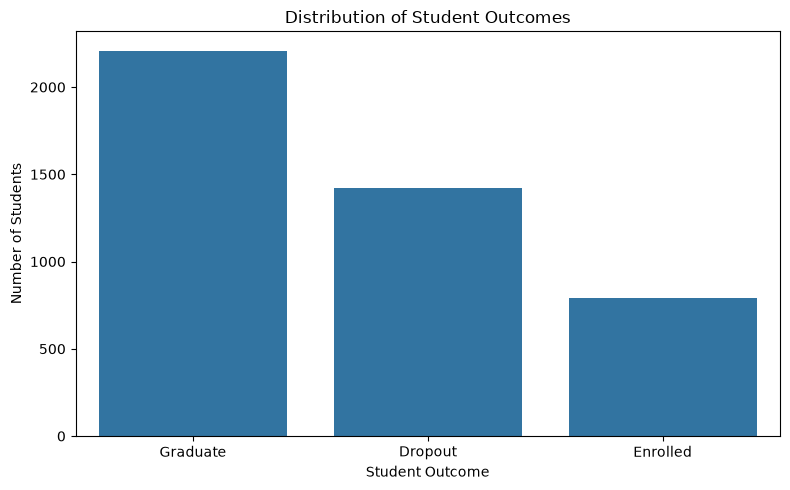

In [173]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=student_dataset,
    x="Target",
    order=student_dataset["Target"].value_counts().index
)

plt.title("Distribution of Student Outcomes")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [174]:
target_summary = pd.DataFrame({
    "Student_Count": target_counts,
    "Percentage": target_percentages
})

target_summary.to_csv(
    "student_outcome_distribution.csv",
    index_label="Target"
)

display(target_summary.round(2))

print("Target distribution summary saved!")

,Student_Count,Percentage
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


Target distribution summary saved!


In [175]:
# PHASE 3 FEATURE ANALYSIS

In [176]:
numerical_features = [
    'Age at enrollment',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (grade)'
]

print("Numerical features defined successfully.")

Numerical features defined successfully.


In [177]:
display(student_dataset[numerical_features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Age at enrollment,4424.0,23.27,7.59,17.0,19.0,20.00,25.0,70.00
Curricular units 1st sem (enrolled),4424.0,6.27,2.48,0.0,5.0,6.00,7.0,26.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.0,3.0,5.00,6.0,26.00
Curricular units 1st sem (evaluations),4424.0,8.30,4.18,0.0,6.0,8.00,10.0,45.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.0,11.0,12.29,13.4,18.88


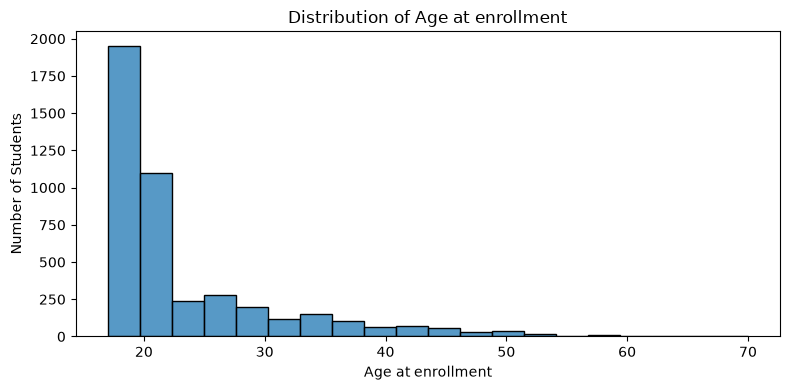

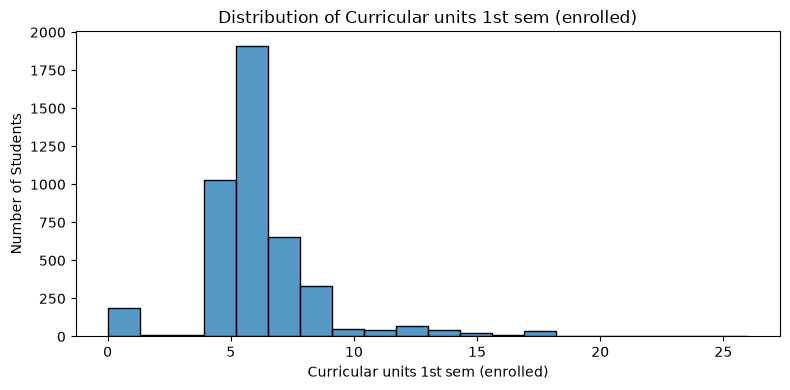

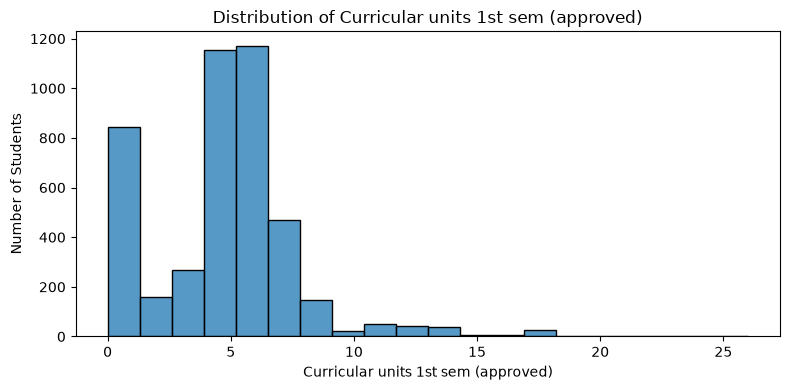

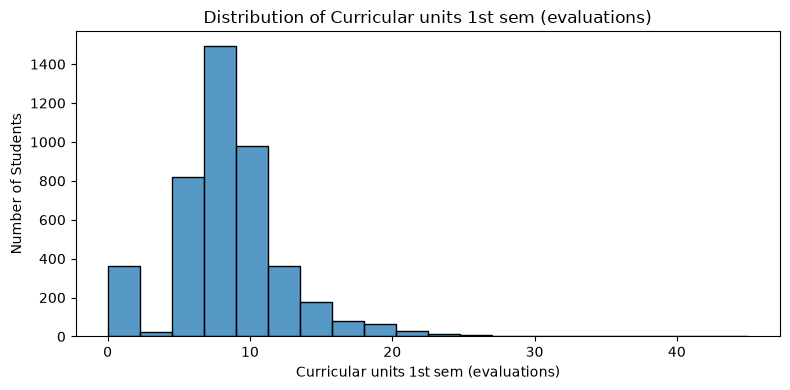

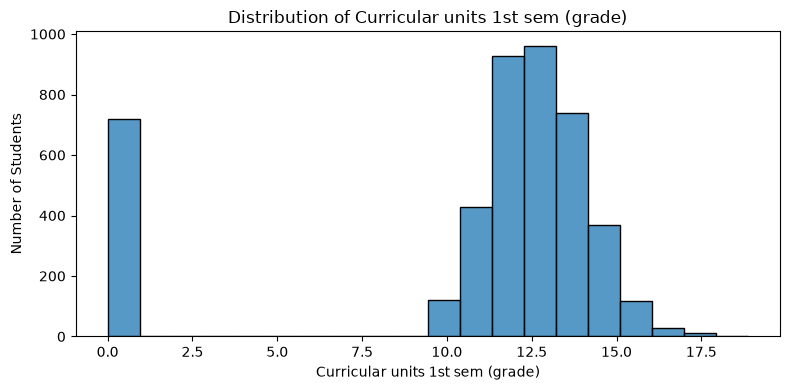

In [178]:
for column in numerical_features:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=student_dataset,
        x=column,
        bins=20
    )

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Number of Students')

    plt.tight_layout()
    plt.show()

In [179]:
categorical_features = [
    'Previous qualification',
    'Tuition fees up to date',
    'Debtor',
    'Scholarship holder'
]

print("Categorical features defined successfully.")

Categorical features defined successfully.


In [180]:
for column in categorical_features:
    print(f"\n{column}")
    print(student_dataset[column].value_counts().sort_index())


Previous qualification
Previous qualification
1     3717
2       23
3      126
4        8
5        1
6       16
7       11
8        4
9       45
10       1
11       2
12     162
13       7
14     219
15      40
16      36
17       6
Name: count, dtype: int64

Tuition fees up to date
Tuition fees up to date
0     528
1    3896
Name: count, dtype: int64

Debtor
Debtor
0    3921
1     503
Name: count, dtype: int64

Scholarship holder
Scholarship holder
0    3325
1    1099
Name: count, dtype: int64


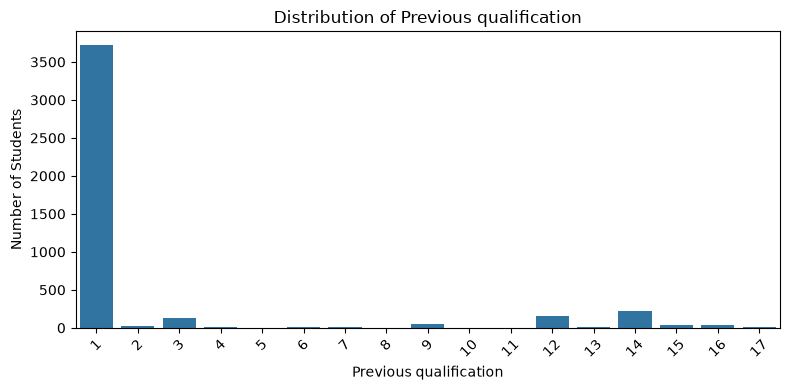

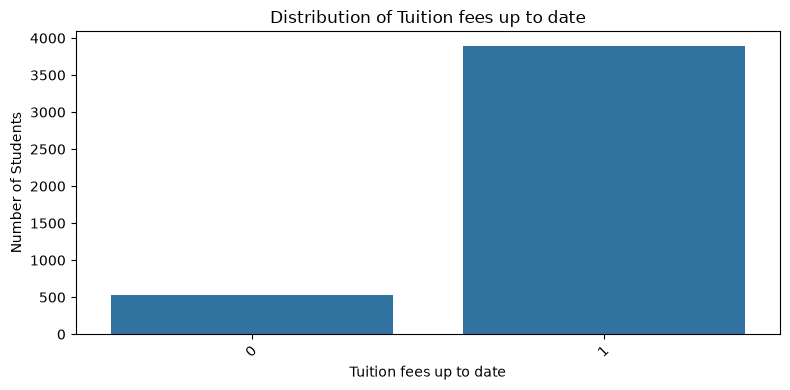

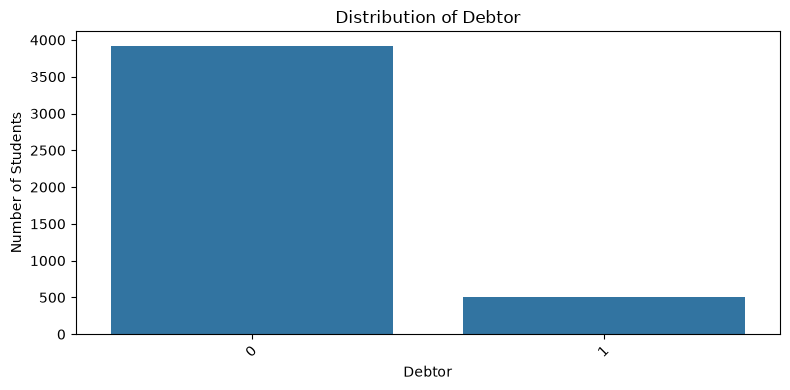

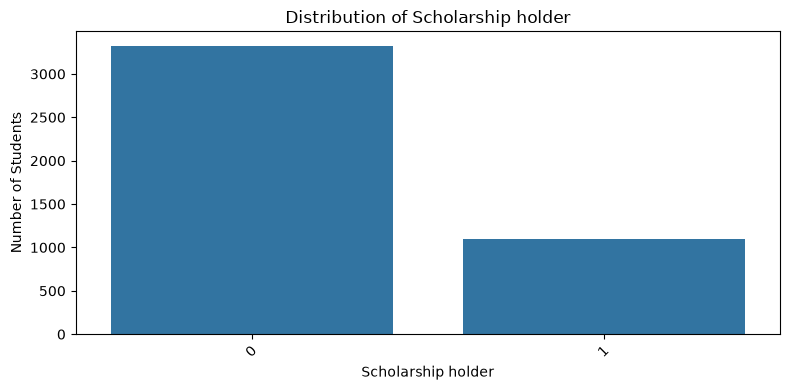

In [181]:
for column in categorical_features:
    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=student_dataset,
        x=column,
        order=sorted(student_dataset[column].unique())
    )

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Number of Students')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

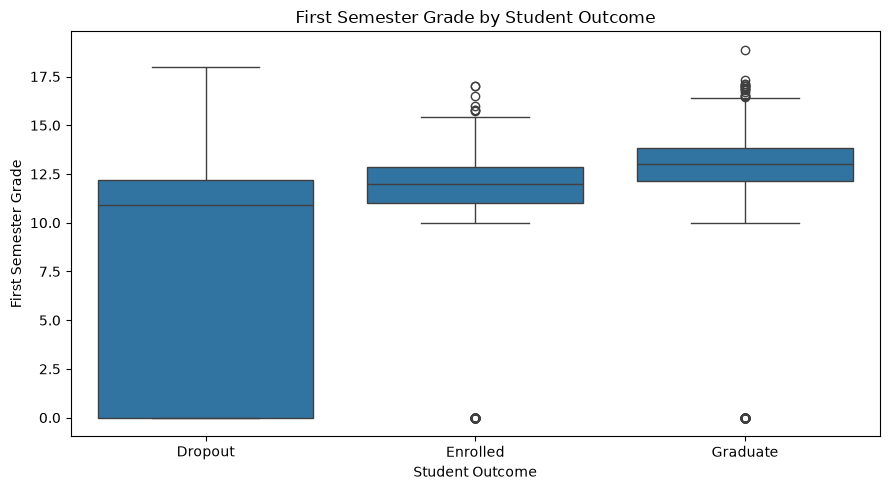

In [182]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=student_dataset,
    x='Target',
    y='Curricular units 1st sem (grade)',
    order=['Dropout', 'Enrolled', 'Graduate']
)

plt.title('First Semester Grade by Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('First Semester Grade')

plt.tight_layout()
plt.show()

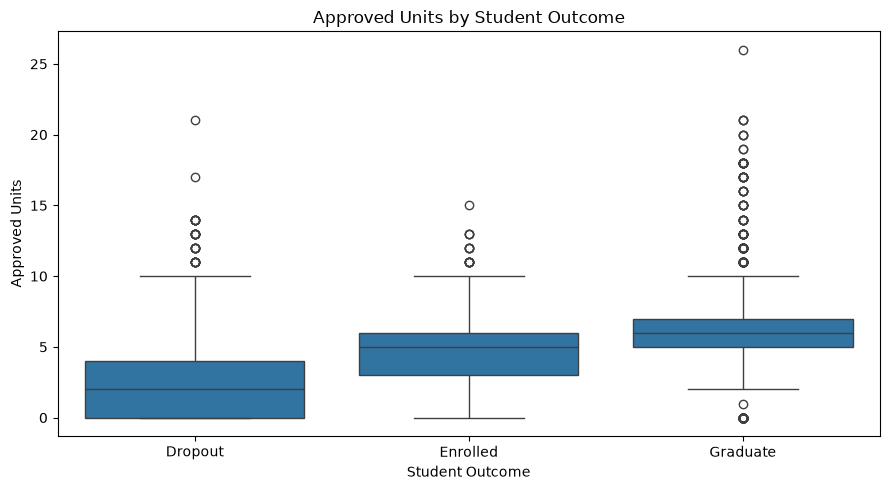

In [183]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=student_dataset,
    x='Target',
    y='Curricular units 1st sem (approved)',
    order=['Dropout', 'Enrolled', 'Graduate']
)

plt.title('Approved Units by Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Approved Units')

plt.tight_layout()
plt.show()

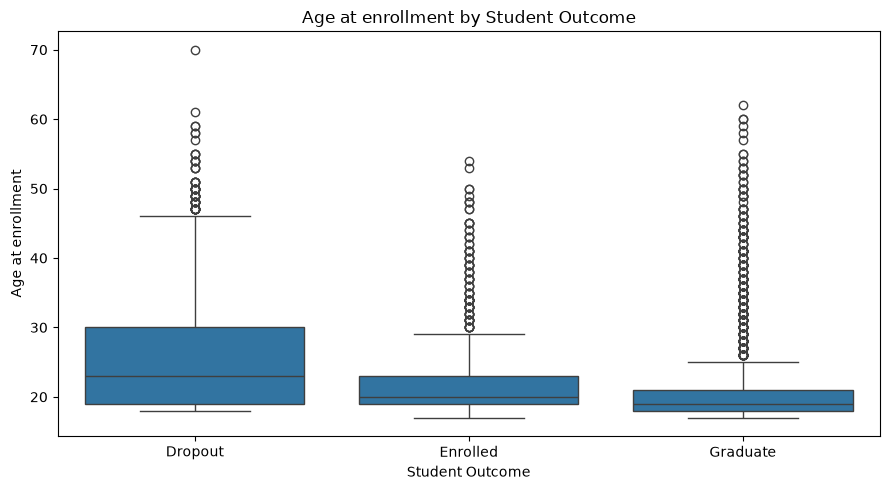

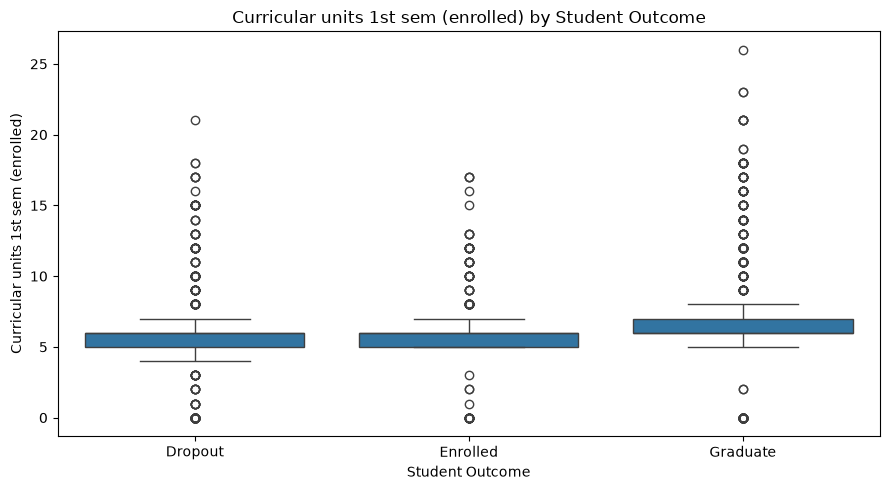

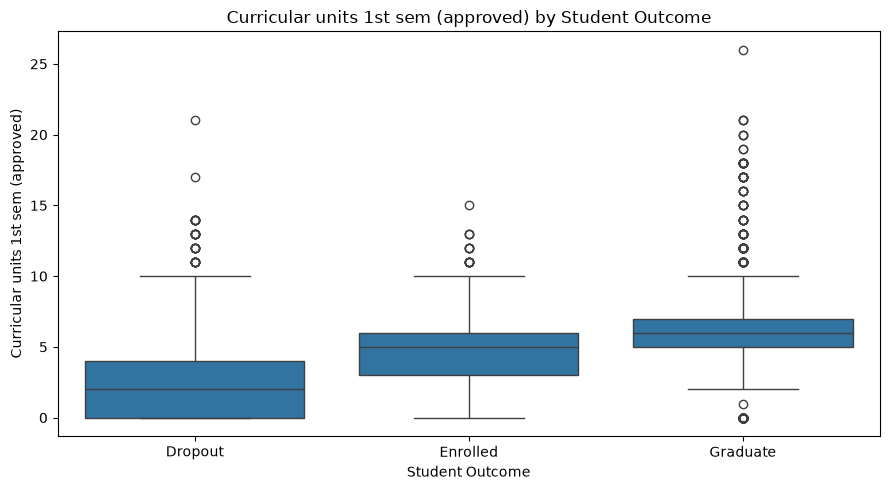

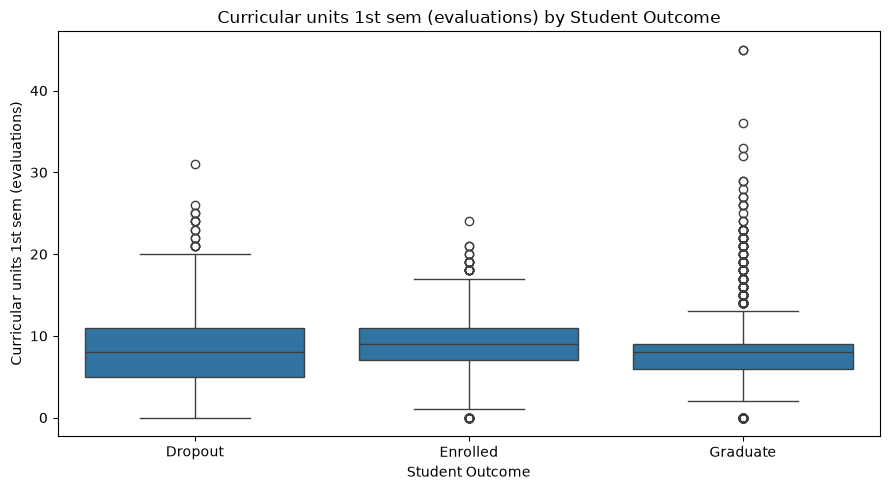

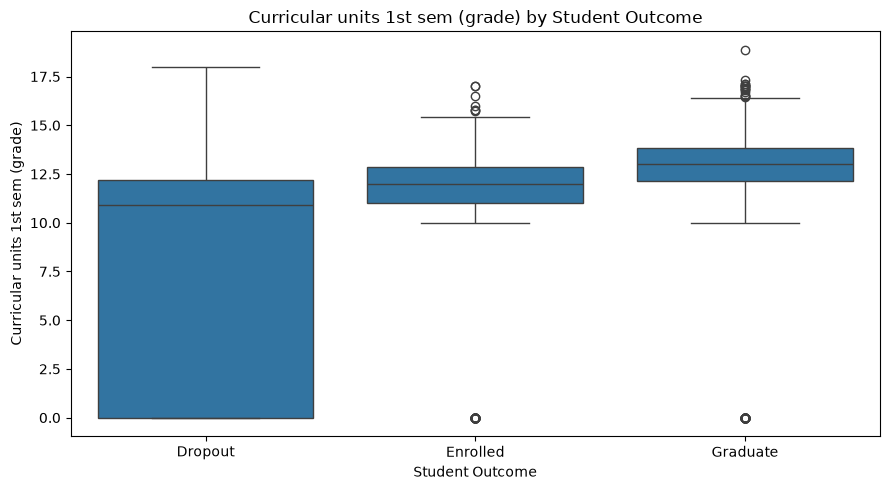

In [184]:
for column in numerical_features:
    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=student_dataset,
        x='Target',
        y=column,
        order=['Dropout', 'Enrolled', 'Graduate']
    )

    plt.title(f'{column} by Student Outcome')
    plt.xlabel('Student Outcome')
    plt.ylabel(column)

    plt.tight_layout()
    plt.show()

In [185]:
tuition_comparison = pd.crosstab(
    student_dataset['Tuition fees up to date'],
    student_dataset['Target'],
    normalize='index'
) * 100

display(tuition_comparison.round(2))

Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,86.55,7.95,5.49
1,24.74,19.30,55.95


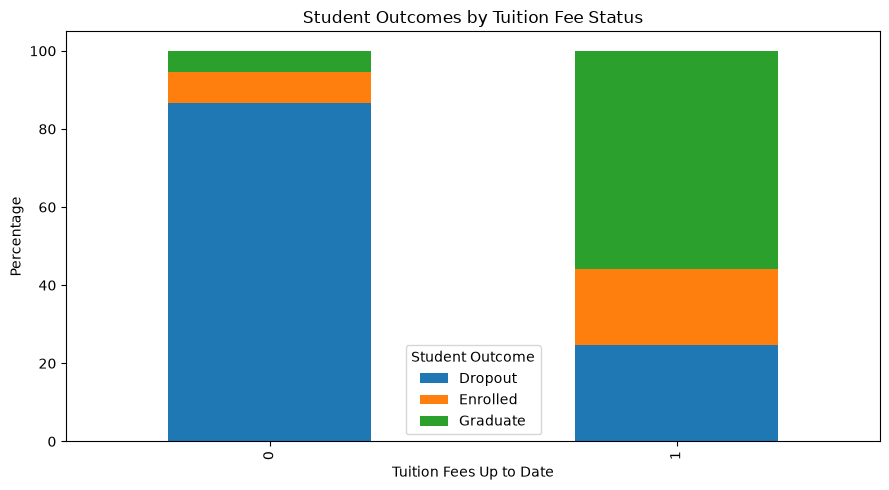

In [186]:
tuition_comparison.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Student Outcomes by Tuition Fee Status')
plt.xlabel('Tuition Fees Up to Date')
plt.ylabel('Percentage')
plt.legend(title='Student Outcome')
plt.tight_layout()
plt.show()

In [187]:
debtor_comparison = pd.crosstab(
    student_dataset['Debtor'],
    student_dataset['Target'],
    normalize='index'
) * 100

display(debtor_comparison.round(2))

Target,Dropout,Enrolled,Graduate
Debtor,,,
0,28.28,17.95,53.76
1,62.03,17.89,20.08


In [188]:
scholarship_comparison = pd.crosstab(
    student_dataset['Scholarship holder'],
    student_dataset['Target'],
    normalize='index'
) * 100

display(scholarship_comparison.round(2))

Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.71,19.97,41.32
1,12.19,11.83,75.98


In [189]:
qualification_comparison = pd.crosstab(
    student_dataset['Previous qualification'],
    student_dataset['Target'],
    normalize='index'
) * 100

display(qualification_comparison.round(2))

Target,Dropout,Enrolled,Graduate
Previous qualification,,,
1,29.00,18.78,52.22
2,69.57,4.35,26.09
3,59.52,3.17,37.30
4,50.00,12.50,37.50
5,100.00,0.00,0.00
6,43.75,6.25,50.00
7,100.00,0.00,0.00
8,75.00,0.00,25.00
9,57.78,13.33,28.89


In [190]:
outcome_comparison = student_dataset.groupby('Target')[
    numerical_features
].agg(['mean', 'median']).round(2)

display(outcome_comparison)

Age at enrollment        Curricular units 1st sem (enrolled)         \
                      mean median                                mean median   
Target                                                                         
Dropout              26.07   23.0                                5.82    6.0   
Enrolled             22.37   20.0                                5.96    6.0   
Graduate             21.78   19.0                                6.67    6.0   

         Curricular units 1st sem (approved)         \
                                        mean median   
Target                                                
Dropout                                 2.55    2.0   
Enrolled                                4.32    5.0   
Graduate                                6.23    6.0   

         Curricular units 1st sem (evaluations)         \
                                           mean median   
Target                                                   
Dropout                                    7.75    8.0   
Enrolled                                   9.34    9.0   
Graduate                                   8.28    8.0   

         Curricular units 1st sem (grade)         
                                     mean median  
Target                                            
Dropout                              7.26  10.93  
Enrolled                            11.13  12.00  
Graduate                            12.64  13.00

In [191]:
# CORRELATION ANALYSIS

In [192]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

numerical_features = [
    'Age at enrollment',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (grade)'
]

correlation_matrix = student_dataset[numerical_features].corr()

display(correlation_matrix.round(2))

,Age at enrollment,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (evaluations),Curricular units 1st sem (grade)
Age at enrollment,1.00,0.14,-0.05,0.14,-0.16
Curricular units 1st sem (enrolled),0.14,1.00,0.77,0.68,0.38
Curricular units 1st sem (approved),-0.05,0.77,1.00,0.52,0.70
Curricular units 1st sem (evaluations),0.14,0.68,0.52,1.00,0.42
Curricular units 1st sem (grade),-0.16,0.38,0.70,0.42,1.00


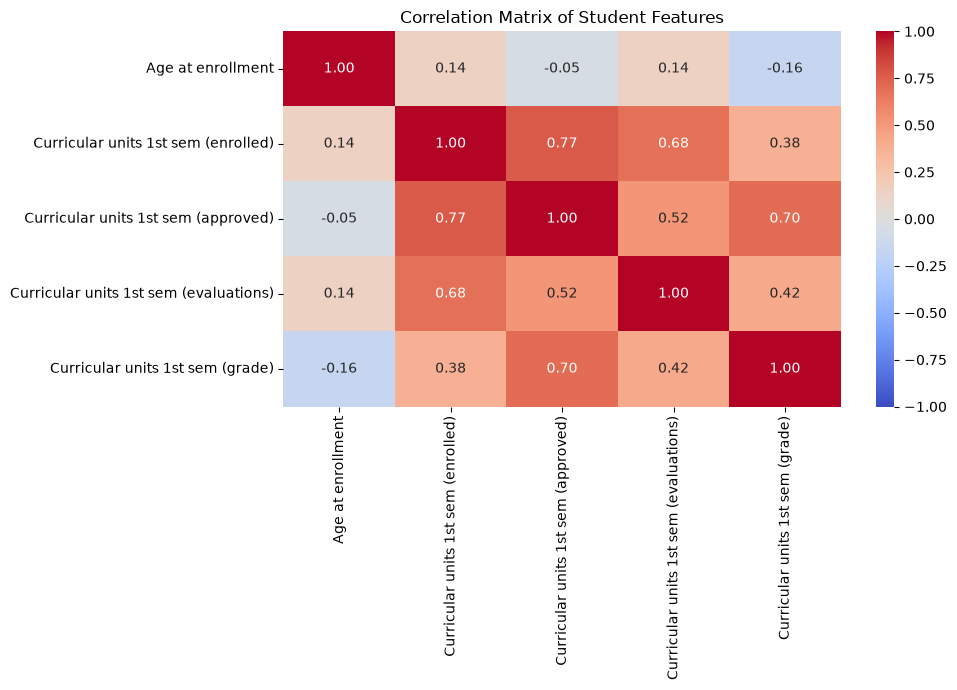

In [193]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix of Student Features')
plt.tight_layout()
plt.show()

In [194]:
outlier_results = []

for column in numerical_features:
    Q1 = student_dataset[column].quantile(0.25)
    Q3 = student_dataset[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (student_dataset[column] < lower_limit) |
        (student_dataset[column] > upper_limit)
    ).sum()

    outlier_results.append({
        'Feature': column,
        'Lower Limit': round(lower_limit, 2),
        'Upper Limit': round(upper_limit, 2),
        'Outlier Count': int(outlier_count)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Feature,Lower Limit,Upper Limit,Outlier Count
0,Age at enrollment,10.0,34.0,441
1,Curricular units 1st sem (enrolled),2.0,10.0,424
2,Curricular units 1st sem (approved),-1.5,10.5,180
3,Curricular units 1st sem (evaluations),0.0,16.0,158
4,Curricular units 1st sem (grade),7.4,17.0,726


In [195]:
# Save the correlation results
correlation_matrix.to_csv('correlation_matrix.csv')

# Save the outlier summary
outlier_summary.to_csv('outlier_summary.csv', index=False)

# Save the numerical comparison by target
outcome_comparison = student_dataset.groupby('Target')[
    numerical_features
].agg(['mean', 'median']).round(2)

outcome_comparison.to_csv('outcome_comparison.csv')

print("EDA summary files saved successfully!")

EDA summary files saved successfully!


In [196]:
# PHASE 4 MACHINE LEARNING

In [197]:
from sklearn.model_selection import train_test_split

# Define the 9 input features
selected_features = [
    'Previous qualification',
    'Age at enrollment',
    'Tuition fees up to date',
    'Debtor',
    'Scholarship holder',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (grade)'
]

# X contains the input features
X = student_dataset[selected_features].copy()

# y contains the target labels
y = student_dataset['Target'].copy()

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (3539, 9)
Testing input shape: (885, 9)

Training target shape: (3539,)
Testing target shape: (885,)


In [198]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = [
    'Previous qualification',
    'Tuition fees up to date',
    'Debtor',
    'Scholarship holder'
]

numerical_features = [
    'Age at enrollment',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (grade)'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'numerical',
            StandardScaler(),
            numerical_features
        ),
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline defined successfully!")

Preprocessing pipeline defined successfully!


In [199]:
from sklearn.dummy import DummyClassifier

# Create a simple baseline model
baseline_model = DummyClassifier(
    strategy='most_frequent'
)

# Train the baseline model
baseline_model.fit(X_train, y_train)

# Predict outcomes for the test dataset
baseline_predictions = baseline_model.predict(X_test)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [200]:
from sklearn.metrics import accuracy_score

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Baseline Accuracy (%):", round(baseline_accuracy * 100, 2), "%")

Baseline Accuracy: 0.4994
Baseline Accuracy (%): 49.94 %


In [201]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and the ML algorithm
logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]
)

print("Logistic Regression pipeline created!")

Logistic Regression pipeline created!


In [202]:
# Train using the training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [203]:
# Predict outcomes for unseen test records
y_pred_logistic = logistic_model.predict(X_test)

print("First 20 actual outcomes:")
print(y_test.iloc[:20].to_list())

print("\nFirst 20 predicted outcomes:")
print(y_pred_logistic[:20])

First 20 actual outcomes:
['Graduate', 'Graduate', 'Enrolled', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Enrolled', 'Dropout', 'Dropout', 'Enrolled', 'Enrolled', 'Graduate', 'Enrolled', 'Dropout', 'Dropout']

First 20 predicted outcomes:
['Graduate' 'Graduate' 'Enrolled' 'Graduate' 'Graduate' 'Graduate'
 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Dropout'
 'Dropout' 'Enrolled' 'Graduate' 'Graduate' 'Graduate' 'Dropout' 'Dropout'
 'Dropout']


In [204]:
#Accuracy alone is not enough because your three classes have different numbers of students
# We WIll calculate four metrics
# Metric	What it measures
# Accuracy	Percentage of all predictions that are correct
# Macro Precision	Average precision across the three classes, giving each equal weight
# Macro Recall	Average recall across the three classes, giving each equal weight
# Macro F1-score	Balanced summary of precision and recall across the three classes 

In [205]:
# CALCULATE THE MATRIX
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate model evaluation metrics
logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

logistic_precision = precision_score(
    y_test,
    y_pred_logistic,
    average='macro',
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    y_pred_logistic,
    average='macro',
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    y_pred_logistic,
    average='macro',
    zero_division=0
)

print("LOGISTIC REGRESSION RESULTS")
print("-" * 35)
print(f"Accuracy:        {logistic_accuracy:.4f}")
print(f"Macro Precision: {logistic_precision:.4f}")
print(f"Macro Recall:    {logistic_recall:.4f}")
print(f"Macro F1-score:  {logistic_f1:.4f}")

LOGISTIC REGRESSION RESULTS
-----------------------------------
Accuracy:        0.7288
Macro Precision: 0.6424
Macro Recall:    0.6148
Macro F1-score:  0.6114


In [206]:
print(
    classification_report(
        y_test,
        y_pred_logistic,
        labels=['Dropout', 'Enrolled', 'Graduate'],
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Dropout       0.74      0.74      0.74       284
    Enrolled       0.42      0.19      0.26       159
    Graduate       0.76      0.92      0.83       442

    accuracy                           0.73       885
   macro avg       0.64      0.61      0.61       885
weighted avg       0.69      0.73      0.70       885



In [207]:
# Create the Confusion Matrix

In [208]:
from sklearn.metrics import confusion_matrix

class_order = ['Dropout', 'Enrolled', 'Graduate']

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=class_order
)

print(cm_logistic)

[[210  26  48]
 [ 51  30  78]
 [ 22  15 405]]


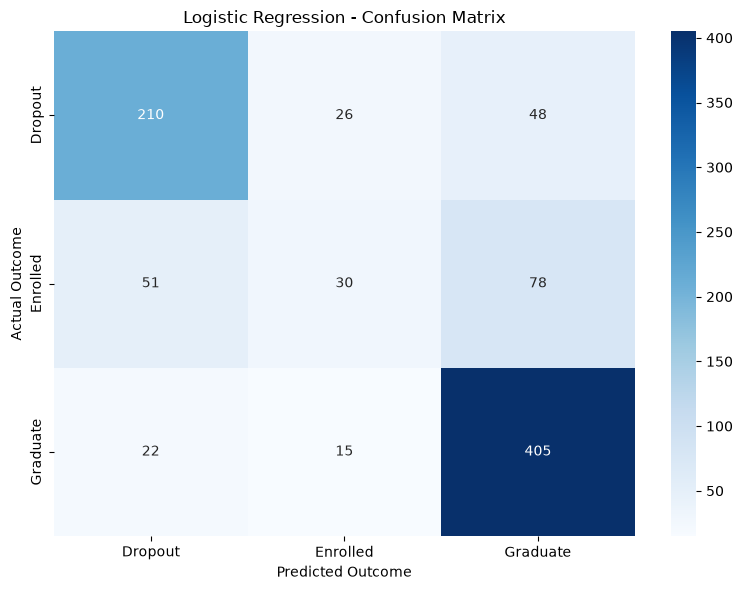

In [209]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')

plt.tight_layout()
plt.show()

In [210]:
logistic_results = pd.DataFrame([{
    'Model': 'Logistic Regression',
    'Accuracy': logistic_accuracy,
    'Macro Precision': logistic_precision,
    'Macro Recall': logistic_recall,
    'Macro F1': logistic_f1
}])

display(logistic_results.round(4))

logistic_results.to_csv(
    'logistic_regression_results.csv',
    index=False
)

print("Logistic Regression results saved!")

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.7288,0.6424,0.6148,0.6114


Logistic Regression results saved!


In [211]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create the Decision Tree pipeline
decision_tree_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ))
    ]
)

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [212]:
# Train the Decision Tree
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [213]:
# Predict outcomes for the test dataset
y_pred_tree = decision_tree_model.predict(X_test)

print("First 20 actual outcomes:")
print(y_test.iloc[:20].to_list())

print("\nFirst 20 predicted outcomes:")
print(y_pred_tree[:20])

First 20 actual outcomes:
['Graduate', 'Graduate', 'Enrolled', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Enrolled', 'Dropout', 'Dropout', 'Enrolled', 'Enrolled', 'Graduate', 'Enrolled', 'Dropout', 'Dropout']

First 20 predicted outcomes:
['Graduate' 'Graduate' 'Dropout' 'Graduate' 'Graduate' 'Graduate'
 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Enrolled'
 'Dropout' 'Dropout' 'Graduate' 'Graduate' 'Graduate' 'Dropout' 'Dropout'
 'Dropout']


In [214]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
tree_accuracy = accuracy_score(y_test, y_pred_tree)

tree_precision = precision_score(
    y_test, y_pred_tree,
    average='macro',
    zero_division=0
)

tree_recall = recall_score(
    y_test, y_pred_tree,
    average='macro',
    zero_division=0
)

tree_f1 = f1_score(
    y_test, y_pred_tree,
    average='macro',
    zero_division=0
)

print("DECISION TREE RESULTS")
print("-" * 35)
print(f"Accuracy:        {tree_accuracy:.4f}")
print(f"Macro Precision: {tree_precision:.4f}")
print(f"Macro Recall:    {tree_recall:.4f}")
print(f"Macro F1-score:  {tree_f1:.4f}")

DECISION TREE RESULTS
-----------------------------------
Accuracy:        0.7299
Macro Precision: 0.6858
Macro Recall:    0.6005
Macro F1-score:  0.5924


In [215]:
print(
    classification_report(
        y_test,
        y_pred_tree,
        labels=['Dropout', 'Enrolled', 'Graduate'],
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Dropout       0.77      0.71      0.74       284
    Enrolled       0.57      0.13      0.21       159
    Graduate       0.72      0.95      0.82       442

    accuracy                           0.73       885
   macro avg       0.69      0.60      0.59       885
weighted avg       0.71      0.73      0.69       885



In [216]:
# Create the Decision Tree Confusion Matrix

In [217]:
from sklearn.metrics import confusion_matrix

class_order = ['Dropout', 'Enrolled', 'Graduate']

cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=class_order
)

print(cm_tree)

[[203  11  70]
 [ 47  21  91]
 [ 15   5 422]]


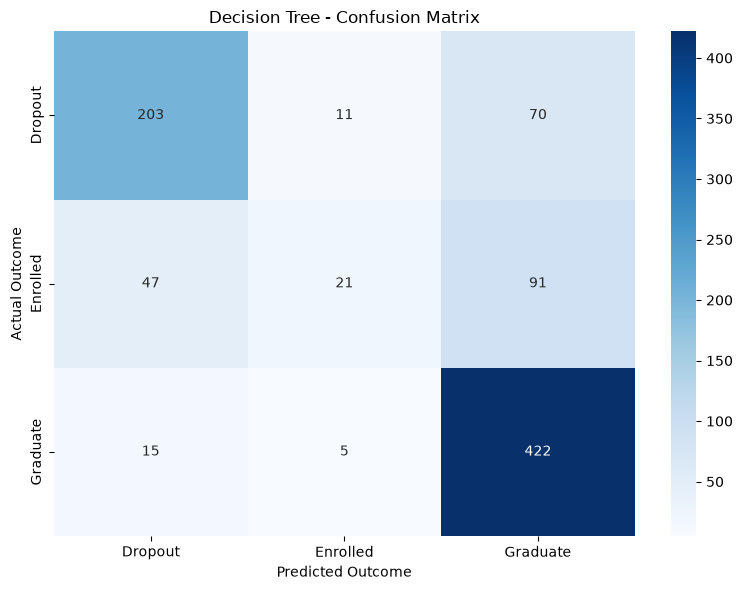

In [218]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')

plt.tight_layout()
plt.show()

In [219]:
tree_results = pd.DataFrame([{
    'Model': 'Decision Tree',
    'Accuracy': tree_accuracy,
    'Macro Precision': tree_precision,
    'Macro Recall': tree_recall,
    'Macro F1': tree_f1
}])

display(tree_results.round(4))

tree_results.to_csv(
    'decision_tree_results.csv',
    index=False
)

print("Decision Tree results saved!")

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Decision Tree,0.7299,0.6858,0.6005,0.5924


Decision Tree results saved!


In [220]:
# Train Model 3: Random Forest

In [221]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [222]:
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [223]:
y_pred_rf = random_forest_model.predict(X_test)

print("First 20 actual outcomes:")
print(y_test.iloc[:20].to_list())

print("\nFirst 20 Random Forest predictions:")
print(y_pred_rf[:20])

First 20 actual outcomes:
['Graduate', 'Graduate', 'Enrolled', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Graduate', 'Enrolled', 'Dropout', 'Dropout', 'Enrolled', 'Enrolled', 'Graduate', 'Enrolled', 'Dropout', 'Dropout']

First 20 Random Forest predictions:
['Graduate' 'Graduate' 'Dropout' 'Graduate' 'Graduate' 'Graduate'
 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Dropout'
 'Dropout' 'Dropout' 'Enrolled' 'Graduate' 'Enrolled' 'Dropout' 'Dropout'
 'Dropout']


In [224]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf,
    average='macro',
    zero_division=0
)

rf_recall = recall_score(
    y_test, y_pred_rf,
    average='macro',
    zero_division=0
)

rf_f1 = f1_score(
    y_test, y_pred_rf,
    average='macro',
    zero_division=0
)

print("RANDOM FOREST RESULTS")
print("-" * 35)
print(f"Accuracy:        {rf_accuracy:.4f}")
print(f"Macro Precision: {rf_precision:.4f}")
print(f"Macro Recall:    {rf_recall:.4f}")
print(f"Macro F1-score:  {rf_f1:.4f}")

RANDOM FOREST RESULTS
-----------------------------------
Accuracy:        0.7062
Macro Precision: 0.6241
Macro Recall:    0.6115
Macro F1-score:  0.6130


In [225]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        labels=['Dropout', 'Enrolled', 'Graduate'],
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Dropout       0.73      0.71      0.72       284
    Enrolled       0.38      0.26      0.31       159
    Graduate       0.77      0.86      0.81       442

    accuracy                           0.71       885
   macro avg       0.62      0.61      0.61       885
weighted avg       0.68      0.71      0.69       885



In [226]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=class_order
)

print(cm_rf)

[[203  33  48]
 [ 49  41  69]
 [ 27  34 381]]


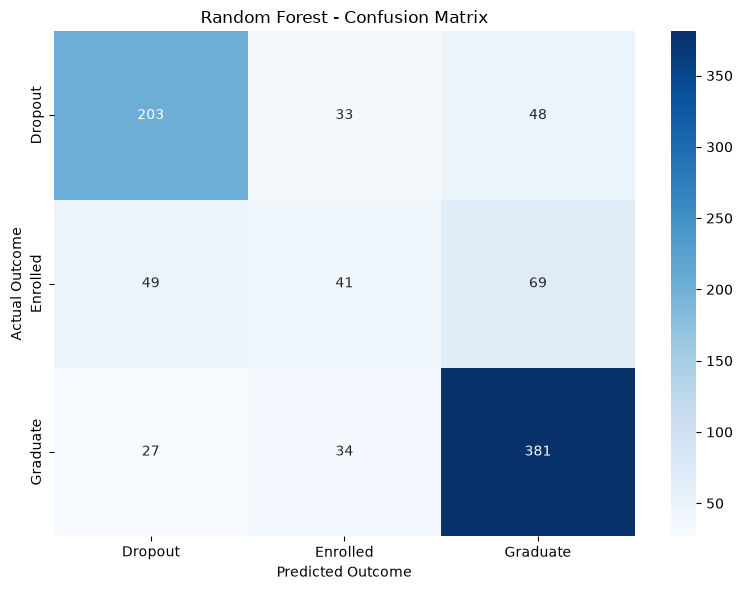

In [227]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')

plt.tight_layout()
plt.show()

In [228]:
rf_results = pd.DataFrame([{
    'Model': 'Random Forest',
    'Accuracy': rf_accuracy,
    'Macro Precision': rf_precision,
    'Macro Recall': rf_recall,
    'Macro F1': rf_f1
}])

display(rf_results.round(4))

rf_results.to_csv(
    'random_forest_results.csv',
    index=False
)

print("Random Forest results saved!")

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest,0.7062,0.6241,0.6115,0.613


Random Forest results saved!


In [229]:
# COMPARE ALL MODELS

In [230]:
model_comparison = pd.DataFrame([
    {
        'Model': 'Baseline',
        'Accuracy': baseline_accuracy,
        'Macro Precision': np.nan,
        'Macro Recall': np.nan,
        'Macro F1': np.nan
    },
    {
        'Model': 'Logistic Regression',
        'Accuracy': logistic_accuracy,
        'Macro Precision': logistic_precision,
        'Macro Recall': logistic_recall,
        'Macro F1': logistic_f1
    },
    {
        'Model': 'Decision Tree',
        'Accuracy': tree_accuracy,
        'Macro Precision': tree_precision,
        'Macro Recall': tree_recall,
        'Macro F1': tree_f1
    },
    {
        'Model': 'Random Forest',
        'Accuracy': rf_accuracy,
        'Macro Precision': rf_precision,
        'Macro Recall': rf_recall,
        'Macro F1': rf_f1
    }
])

display(
    model_comparison.round(4).sort_values(
        by='Macro F1',
        ascending=False,
        na_position='last'
    )
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
3,Random Forest,0.7062,0.6241,0.6115,0.6130
1,Logistic Regression,0.7288,0.6424,0.6148,0.6114
2,Decision Tree,0.7299,0.6858,0.6005,0.5924
0,Baseline,0.4994,NaN,NaN,NaN


In [231]:
model_comparison.to_csv(
    'model_comparison.csv',
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


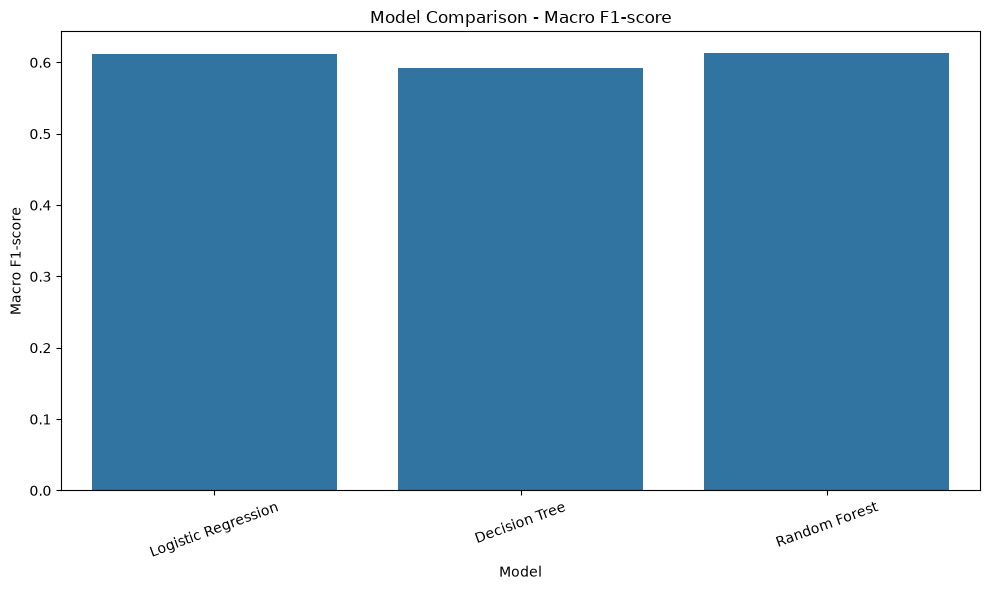

In [232]:
plot_data = model_comparison.dropna(subset=['Macro F1'])

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x='Model',
    y='Macro F1'
)

plt.title('Model Comparison - Macro F1-score')
plt.xlabel('Model')
plt.ylabel('Macro F1-score')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [233]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Measure the importance of the original input features
perm_result = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    scoring='f1_macro',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create a readable results table
permutation_importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance Mean': perm_result.importances_mean,
    'Importance Std': perm_result.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by='Importance Mean',
    ascending=False
)

display(permutation_importance_df.round(4))


,Feature,Importance Mean,Importance Std
6,Curricular units 1st sem (approved),0.1369,0.0090
2,Tuition fees up to date,0.0463,0.0092
1,Age at enrollment,0.0183,0.0052
7,Curricular units 1st sem (evaluations),0.0097,0.0107
0,Previous qualification,0.0086,0.0037
3,Debtor,0.0076,0.0027
8,Curricular units 1st sem (grade),0.0069,0.0131
4,Scholarship holder,0.0056,0.0030
5,Curricular units 1st sem (enrolled),0.0055,0.0082


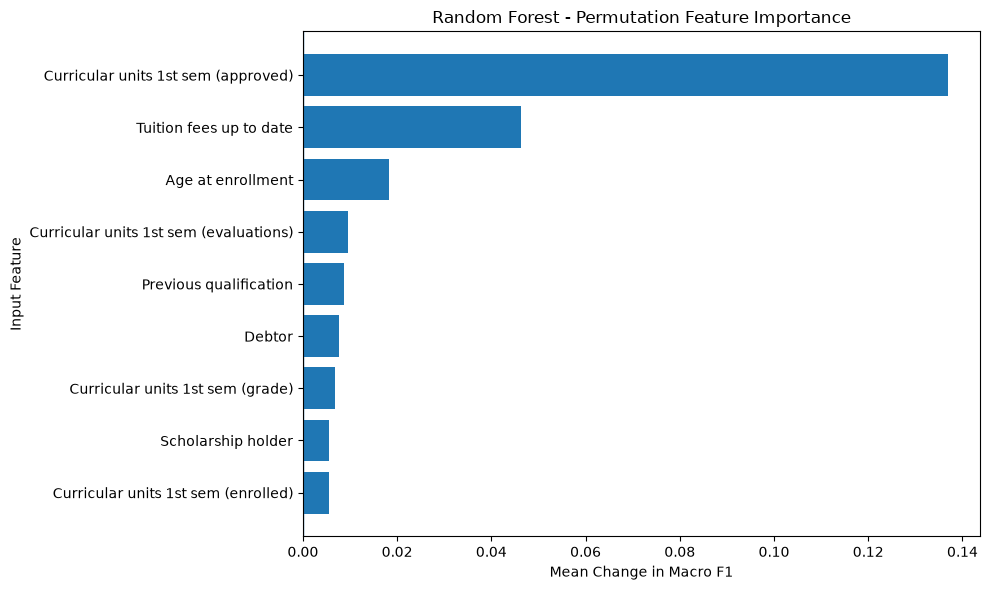

In [234]:

plt.figure(figsize=(10, 6))

plot_data = permutation_importance_df.sort_values(
    by='Importance Mean',
    ascending=True
)

plt.barh(
    plot_data['Feature'],
    plot_data['Importance Mean']
)

plt.axvline(0, linewidth=1)
plt.title('Random Forest - Permutation Feature Importance')
plt.xlabel('Mean Change in Macro F1')
plt.ylabel('Input Feature')

plt.tight_layout()
plt.show()


In [235]:

permutation_importance_df.to_csv(
    'permutation_feature_importance.csv',
    index=False
)

print("Feature importance results saved successfully!")


Feature importance results saved successfully!


In [236]:
# Hyperparameter Tuning

In [237]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_tuning_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ]
)

print("Random Forest tuning pipeline created!")


Random Forest tuning pipeline created!


In [238]:

param_distributions = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': [None, 'balanced']
}

print("Hyperparameter search space defined!")


Hyperparameter search space defined!


In [239]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring='f1_macro',
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Fit and tune using training data only
random_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Hyperparameter tuning completed!


In [240]:

print("Best Parameters:")
print(random_search.best_params_)

print(
    "\nBest Cross-Validation Macro F1:",
    round(random_search.best_score_, 4)
)


Best Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None, 'classifier__class_weight': 'balanced'}

Best Cross-Validation Macro F1: 0.6663


In [241]:
# Evaluate the Tuned Random Forest

In [242]:

tuned_rf_model = random_search.best_estimator_

y_pred_tuned_rf = tuned_rf_model.predict(X_test)

print("Tuned Random Forest predictions generated!")


Tuned Random Forest predictions generated!


In [243]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

tuned_rf_accuracy = accuracy_score(
    y_test, y_pred_tuned_rf
)

tuned_rf_precision = precision_score(
    y_test,
    y_pred_tuned_rf,
    average='macro',
    zero_division=0
)

tuned_rf_recall = recall_score(
    y_test,
    y_pred_tuned_rf,
    average='macro',
    zero_division=0
)

tuned_rf_f1 = f1_score(
    y_test,
    y_pred_tuned_rf,
    average='macro',
    zero_division=0
)

print("TUNED RANDOM FOREST RESULTS")
print("-" * 35)
print(f"Accuracy:        {tuned_rf_accuracy:.4f}")
print(f"Macro Precision: {tuned_rf_precision:.4f}")
print(f"Macro Recall:    {tuned_rf_recall:.4f}")
print(f"Macro F1-score:  {tuned_rf_f1:.4f}")


TUNED RANDOM FOREST RESULTS
-----------------------------------
Accuracy:        0.7028
Macro Precision: 0.6750
Macro Recall:    0.6791
Macro F1-score:  0.6660


In [244]:

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_tuned_rf,
        labels=['Dropout', 'Enrolled', 'Graduate'],
        zero_division=0
    )
)


              precision    recall  f1-score   support

     Dropout       0.78      0.66      0.71       284
    Enrolled       0.39      0.62      0.48       159
    Graduate       0.86      0.76      0.81       442

    accuracy                           0.70       885
   macro avg       0.67      0.68      0.67       885
weighted avg       0.75      0.70      0.72       885



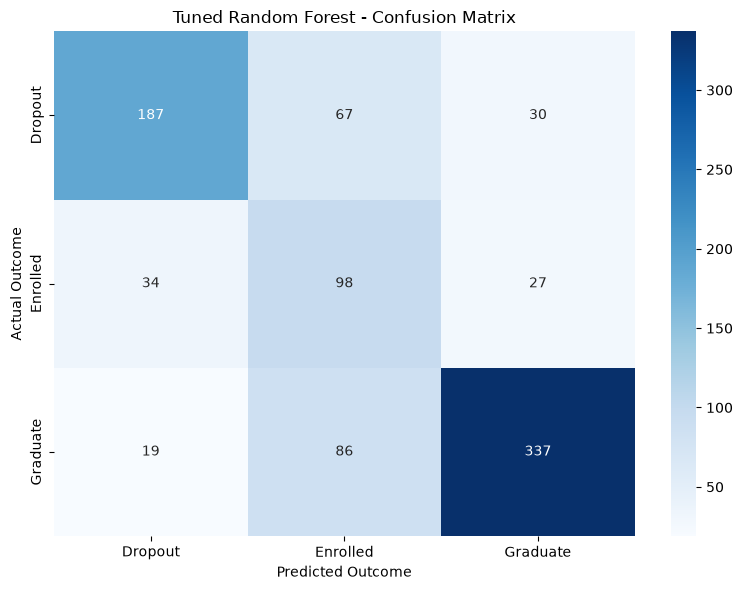

In [245]:

from sklearn.metrics import confusion_matrix

class_order = ['Dropout', 'Enrolled', 'Graduate']

cm_tuned_rf = confusion_matrix(
    y_test,
    y_pred_tuned_rf,
    labels=class_order
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tuned_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_order,
    yticklabels=class_order
)

plt.title('Tuned Random Forest - Confusion Matrix')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')

plt.tight_layout()
plt.show()


In [246]:
# Compare the Original and Tuned Models

In [247]:

tuning_comparison = pd.DataFrame([
    {
        'Model': 'Original Random Forest',
        'Accuracy': rf_accuracy,
        'Macro Precision': rf_precision,
        'Macro Recall': rf_recall,
        'Macro F1': rf_f1
    },
    {
        'Model': 'Tuned Random Forest',
        'Accuracy': tuned_rf_accuracy,
        'Macro Precision': tuned_rf_precision,
        'Macro Recall': tuned_rf_recall,
        'Macro F1': tuned_rf_f1
    }
])

display(
    tuning_comparison.sort_values(
        by='Macro F1',
        ascending=False
    ).round(4)
)

tuning_comparison.to_csv(
    'random_forest_tuning_comparison.csv',
    index=False
)

print("Tuning comparison saved!")


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
1,Tuned Random Forest,0.7028,0.6750,0.6791,0.666
0,Original Random Forest,0.7062,0.6241,0.6115,0.613


Tuning comparison saved!


In [248]:
# Compare all five candidates

In [249]:

final_model_results = pd.DataFrame([
    {
        'Model': 'Baseline',
        'Accuracy': baseline_accuracy,
        'Macro Precision': np.nan,
        'Macro Recall': np.nan,
        'Macro F1': np.nan
    },
    {
        'Model': 'Logistic Regression',
        'Accuracy': logistic_accuracy,
        'Macro Precision': logistic_precision,
        'Macro Recall': logistic_recall,
        'Macro F1': logistic_f1
    },
    {
        'Model': 'Decision Tree',
        'Accuracy': tree_accuracy,
        'Macro Precision': tree_precision,
        'Macro Recall': tree_recall,
        'Macro F1': tree_f1
    },
    {
        'Model': 'Random Forest',
        'Accuracy': rf_accuracy,
        'Macro Precision': rf_precision,
        'Macro Recall': rf_recall,
        'Macro F1': rf_f1
    },
    {
        'Model': 'Tuned Random Forest',
        'Accuracy': tuned_rf_accuracy,
        'Macro Precision': tuned_rf_precision,
        'Macro Recall': tuned_rf_recall,
        'Macro F1': tuned_rf_f1
    }
])

display(
    final_model_results.sort_values(
        by='Macro F1',
        ascending=False,
        na_position='last'
    ).round(4)
)

final_model_results.to_csv(
    'final_model_comparison.csv',
    index=False
)

print("Final model comparison saved!")


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
4,Tuned Random Forest,0.7028,0.6750,0.6791,0.6660
3,Random Forest,0.7062,0.6241,0.6115,0.6130
1,Logistic Regression,0.7288,0.6424,0.6148,0.6114
2,Decision Tree,0.7299,0.6858,0.6005,0.5924
0,Baseline,0.4994,NaN,NaN,NaN


Final model comparison saved!


In [250]:
# PHASE 4 Finalize the Machine Learning Model

In [251]:
display(
    final_model_results.sort_values(
        by="Macro F1",
        ascending=False,
        na_position="last"
    ).round(4)
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
4,Tuned Random Forest,0.7028,0.6750,0.6791,0.6660
3,Random Forest,0.7062,0.6241,0.6115,0.6130
1,Logistic Regression,0.7288,0.6424,0.6148,0.6114
2,Decision Tree,0.7299,0.6858,0.6005,0.5924
0,Baseline,0.4994,NaN,NaN,NaN


In [252]:
# Map model names to their trained pipelines
model_candidates = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Tuned Random Forest": tuned_rf_model
}

# Exclude the baseline and keep actual classification models
candidate_results = final_model_results[
    final_model_results["Model"].isin(model_candidates)
].dropna(subset=["Macro F1"]).copy()

if candidate_results.empty:
    raise ValueError(
        "No model results found. Check final_model_results."
    )

# Rank candidates by macro F1
candidate_results = candidate_results.sort_values(
    by="Macro F1",
    ascending=False
)

display(candidate_results.round(4))

# Select the highest-scoring candidate
selected_model_name = candidate_results.iloc[0]["Model"]
final_model = model_candidates[selected_model_name]

print("Selected model:", selected_model_name)
print(
    "Test-set macro F1:",
    round(candidate_results.iloc[0]["Macro F1"], 4)
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
4,Tuned Random Forest,0.7028,0.6750,0.6791,0.6660
3,Random Forest,0.7062,0.6241,0.6115,0.6130
1,Logistic Regression,0.7288,0.6424,0.6148,0.6114
2,Decision Tree,0.7299,0.6858,0.6005,0.5924


Selected model: Tuned Random Forest
Test-set macro F1: 0.666


In [253]:
from sklearn.metrics import classification_report

final_predictions = final_model.predict(X_test)

print("Selected model:", selected_model_name)
print("\nFinal classification report:\n")

print(
    classification_report(
        y_test,
        final_predictions,
        labels=["Dropout", "Enrolled", "Graduate"],
        zero_division=0
    )
)

Selected model: Tuned Random Forest

Final classification report:

              precision    recall  f1-score   support

     Dropout       0.78      0.66      0.71       284
    Enrolled       0.39      0.62      0.48       159
    Graduate       0.86      0.76      0.81       442

    accuracy                           0.70       885
   macro avg       0.67      0.68      0.67       885
weighted avg       0.75      0.70      0.72       885



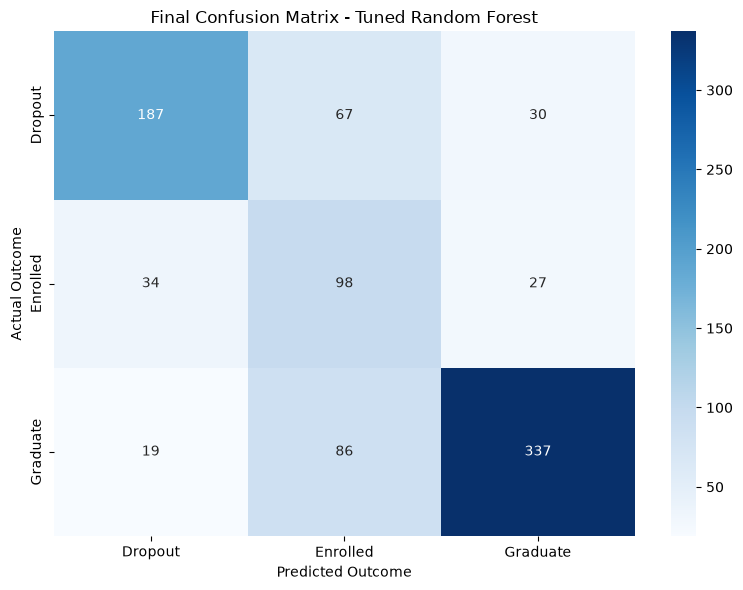

In [254]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

class_order = ["Dropout", "Enrolled", "Graduate"]

final_cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=class_order
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_order,
    yticklabels=class_order
)

plt.title(f"Final Confusion Matrix - {selected_model_name}")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.tight_layout()
plt.show()

In [255]:
sample_student = X_test.iloc[[0]]

display(sample_student)

,Previous qualification,Age at enrollment,Tuition fees up to date,Debtor,Scholarship holder,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (evaluations),Curricular units 1st sem (grade)
1853,14,20,1,0,0,6,6,7,14.0


In [256]:
sample_prediction = final_model.predict(sample_student)[0]

print("Predicted student outcome:", sample_prediction)

Predicted student outcome: Graduate


In [257]:
sample_probabilities = final_model.predict_proba(
    sample_student
)[0]

probability_table = pd.DataFrame({
    "Outcome": final_model.named_steps["classifier"].classes_,
    "Predicted Probability": sample_probabilities
})

probability_table["Predicted Probability (%)"] = (
    probability_table["Predicted Probability"] * 100
)

display(
    probability_table.sort_values(
        by="Predicted Probability",
        ascending=False
    ).round(2)
)

,Outcome,Predicted Probability,Predicted Probability (%)
2,Graduate,0.81,80.67
1,Enrolled,0.13,12.84
0,Dropout,0.06,6.49


In [258]:
# Save your final model

In [259]:
import joblib
import json
from pathlib import Path

# Create a folder for saved model files
model_folder = Path("saved_model")
model_folder.mkdir(exist_ok=True)

# Save the complete preprocessing + model pipeline
model_path = model_folder / "student_outcome_final_model.joblib"

joblib.dump(final_model, model_path)

print("Final model saved successfully!")
print("Location:", model_path.resolve())

Final model saved successfully!
Location: C:\Users\shant\saved_model\student_outcome_final_model.joblib


In [260]:
features_path = model_folder / "selected_features.json"

with open(features_path, "w", encoding="utf-8") as file:
    json.dump(selected_features, file, indent=4)

print("Feature list saved successfully!")

Feature list saved successfully!


In [261]:
model_details = {
    "model_name": selected_model_name,
    "target_column": "Target",
    "target_classes": ["Dropout", "Enrolled", "Graduate"],
    "selection_metric": "Macro F1",
    "test_accuracy": float(
        (final_predictions == y_test.to_numpy()).mean()
    ),
    "test_macro_f1": float(
        candidate_results.loc[
            candidate_results["Model"] == selected_model_name,
            "Macro F1"
        ].iloc[0]
    ),
    "input_features": selected_features
}

metadata_path = model_folder / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(model_details, file, indent=4)

print("Model metadata saved successfully!")

Model metadata saved successfully!


In [262]:
# Verify the saved model

In [263]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Predict using the loaded model
loaded_prediction = loaded_model.predict(sample_student)[0]

print("Original model prediction:", sample_prediction)
print("Reloaded model prediction:", loaded_prediction)

assert loaded_prediction == sample_prediction

print("\nModel verification successful!")

Original model prediction: Graduate
Reloaded model prediction: Graduate

Model verification successful!


In [264]:
# PHASE 5

In [265]:
# BuildING THE Student Outcome Prediction Application

In [266]:
from pathlib import Path

print("Project folder:", Path.cwd())

required_files = [
    Path("student_outcome_dataset.csv"),
    Path("saved_model/student_outcome_final_model.joblib"),
    Path("saved_model/selected_features.json")
]

for file_path in required_files:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status}: {file_path}")

Project folder: C:\Users\shant
FOUND: student_outcome_dataset.csv
FOUND: saved_model\student_outcome_final_model.joblib
FOUND: saved_model\selected_features.json


In [267]:
# Install Streamlit

In [268]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [269]:
import streamlit as st

print("Streamlit version:", st.__version__)

Streamlit version: 1.58.0


In [270]:
# Create the application file

In [271]:
import sys

print("Python environment:", sys.executable)

Python environment: C:\Users\shant\anaconda3\python.exe


In [272]:
%%writefile app.py

from pathlib import Path
import json

import joblib
import pandas as pd
import streamlit as st

# 1. Application configuration

st.set_page_config(
    page_title="Student Outcome Prediction",
    page_icon="🎓",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent

MODEL_PATH = (
    BASE_DIR / "saved_model" / "student_outcome_final_model.joblib"
)

FEATURES_PATH = (
    BASE_DIR / "saved_model" / "selected_features.json"
)

DATA_PATH = BASE_DIR / "student_outcome_dataset.csv"


# 2. Check required files

required_paths = [
    MODEL_PATH,
    FEATURES_PATH,
    DATA_PATH
]

missing_paths = [
    str(path) for path in required_paths
    if not path.exists()
]

if missing_paths:
    st.error("Some required project files are missing.")
    st.write(missing_paths)
    st.info(
        "Keep app.py beside student_outcome_dataset.csv "
        "and the saved_model folder."
    )
    st.stop()

# 3. Load model, features and dataset


@st.cache_resource
def load_model(path):
    return joblib.load(path)


@st.cache_data
def load_dataset(path):
    return pd.read_csv(path)


model = load_model(str(MODEL_PATH))
student_data = load_dataset(str(DATA_PATH))

with open(FEATURES_PATH, "r", encoding="utf-8") as file:
    selected_features = json.load(file)


# Validate that the feature list matches the dataset
missing_columns = [
    column for column in selected_features
    if column not in student_data.columns
]

if missing_columns:
    st.error(
        f"Required dataset columns are missing: {missing_columns}"
    )
    st.stop()

# 4. Helper functions for input ranges

def integer_bounds(column):
    values = pd.to_numeric(
        student_data[column],
        errors="coerce"
    ).dropna()

    return (
        int(values.min()),
        int(values.max()),
        int(round(values.median()))
    )


# 5. Application heading


st.title("🎓 Student Outcome Prediction System")

st.write(
    "Enter student information to predict a likely academic "
    "outcome using the trained machine learning model."
)

st.caption(
    "This model uses the selected demographic and first-semester "
    "academic features. Predictions are estimates, not guarantees."
)

st.divider()


# 6. Student input form

qualification_options = sorted(
    student_data["Previous qualification"]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

if not qualification_options:
    st.error("No previous qualification categories were found.")
    st.stop()


age_min, age_max, age_default = integer_bounds(
    "Age at enrollment"
)

enrolled_min, enrolled_max, enrolled_default = integer_bounds(
    "Curricular units 1st sem (enrolled)"
)

approved_min, approved_max, approved_default = integer_bounds(
    "Curricular units 1st sem (approved)"
)

evaluations_min, evaluations_max, evaluations_default = integer_bounds(
    "Curricular units 1st sem (evaluations)"
)

grade_min = float(
    student_data["Curricular units 1st sem (grade)"].min()
)

grade_max = float(
    student_data["Curricular units 1st sem (grade)"].max()
)

grade_default = float(
    student_data["Curricular units 1st sem (grade)"].median()
)


with st.form("student_prediction_form"):

    col1, col2 = st.columns(2)

    with col1:
        st.subheader("Student Information")

        previous_qualification = st.selectbox(
            "Previous qualification (dataset code)",
            options=qualification_options
        )

        age = st.number_input(
            "Age at enrollment",
            min_value=age_min,
            max_value=age_max,
            value=age_default,
            step=1
        )

        tuition_status = st.selectbox(
            "Tuition fees up to date",
            options=[1, 0],
            format_func=lambda value: (
                "Yes" if value == 1 else "No"
            )
        )

        debtor_status = st.selectbox(
            "Debtor",
            options=[0, 1],
            format_func=lambda value: (
                "No" if value == 0 else "Yes"
            )
        )

        scholarship_status = st.selectbox(
            "Scholarship holder",
            options=[0, 1],
            format_func=lambda value: (
                "No" if value == 0 else "Yes"
            )
        )

    with col2:
        st.subheader("First-Semester Performance")

        enrolled_units = st.number_input(
            "Curricular units enrolled",
            min_value=enrolled_min,
            max_value=enrolled_max,
            value=enrolled_default,
            step=1
        )

        approved_units = st.number_input(
            "Curricular units approved",
            min_value=approved_min,
            max_value=approved_max,
            value=approved_default,
            step=1
        )

        evaluations = st.number_input(
            "Curricular units evaluations",
            min_value=evaluations_min,
            max_value=evaluations_max,
            value=evaluations_default,
            step=1
        )

        first_semester_grade = st.number_input(
            "First-semester grade",
            min_value=grade_min,
            max_value=grade_max,
            value=grade_default,
            step=0.1,
            format="%.2f"
        )

    submitted = st.form_submit_button(
        "Predict Student Outcome",
        use_container_width=True
    )


# 7. Run prediction

if submitted:

    if approved_units > enrolled_units:
        st.warning(
            "Approved units cannot exceed enrolled units. "
            "Please check these inputs."
        )

    else:
        input_values = {
            "Previous qualification": previous_qualification,
            "Age at enrollment": age,
            "Tuition fees up to date": tuition_status,
            "Debtor": debtor_status,
            "Scholarship holder": scholarship_status,
            "Curricular units 1st sem (enrolled)": enrolled_units,
            "Curricular units 1st sem (approved)": approved_units,
            "Curricular units 1st sem (evaluations)": evaluations,
            "Curricular units 1st sem (grade)": first_semester_grade
        }

        input_df = pd.DataFrame(
            [input_values],
            columns=selected_features
        )

        try:
            prediction = model.predict(input_df)[0]

            st.divider()
            st.subheader("Prediction Result")

            st.metric(
                label="Predicted Student Outcome",
                value=str(prediction)
            )

            st.caption(
                "The result is a model prediction, not a confirmed "
                "future outcome or a causal assessment."
            )

            # Display estimated class probabilities
            if hasattr(model, "predict_proba"):

                probabilities = model.predict_proba(input_df)[0]

                classifier = model.named_steps["classifier"]
                classes = classifier.classes_

                probability_df = pd.DataFrame({
                    "Outcome": classes,
                    "Estimated probability (%)": probabilities * 100
                })

                probability_df = probability_df.sort_values(
                    "Estimated probability (%)",
                    ascending=False
                )

                st.subheader("Estimated Class Probabilities")

                display_df = probability_df.copy()
                display_df["Estimated probability (%)"] = (
                    display_df["Estimated probability (%)"].round(2)
                )

                st.dataframe(
                    display_df,
                    use_container_width=True,
                    hide_index=True
                )

                st.bar_chart(
                    probability_df.set_index("Outcome")[
                        "Estimated probability (%)"
                    ]
                )

        except Exception as error:
            st.error(f"Prediction failed: {error}")

Overwriting app.py


In [273]:
import sys

print("Python environment:", sys.executable)

Python environment: C:\Users\shant\anaconda3\python.exe


In [274]:
from pathlib import Path

print("Current project folder:")
print(Path.cwd())

required_files = [
    "app.py",
    "student_outcome_dataset.csv",
    "saved_model/student_outcome_final_model.joblib",
    "saved_model/selected_features.json"
]

print("\nChecking required files:")

for name in required_files:
    file_path = Path(name)
    status = "FOUND" if file_path.exists() else "MISSING"
    print(status, "-", name)

Current project folder:
C:\Users\shant

Checking required files:
FOUND - app.py
FOUND - student_outcome_dataset.csv
FOUND - saved_model/student_outcome_final_model.joblib
FOUND - saved_model/selected_features.json


In [275]:
import sys

print("Python executable:")
print(sys.executable)

Python executable:
C:\Users\shant\anaconda3\python.exe


In [276]:
from pathlib import Path

# Find the folder where Jupyter is currently working
project_folder = Path.cwd()

print("YOUR CURRENT PROJECT FOLDER IS:")
print(project_folder)

print("\nFILES AND FOLDERS INSIDE IT:")

for item in project_folder.iterdir():
    print(item.name)

YOUR CURRENT PROJECT FOLDER IS:
C:\Users\shant

FILES AND FOLDERS INSIDE IT:
.accessibility.properties
.anaconda
.android
.cache
.conda
.continuum
.copilot
.cursor
.gemini
.git-for-windows-updater
.gitconfig
.idlerc
.ipynb_checkpoints
.ipython
.jupyter
.ollama
.packettracer
.python_history
.redhat
.VirtualBox
.vscode
.vscode-shared
anaconda3
app.py
AppData
Application Data
Cisco Packet Tracer 7.3.0
COLLEGE PROJECT Untitled4.ipynb
Contacts
Cookies
correlation_matrix.csv
creditcard.csv
CrossDevice
dataset.csv
dataset_cleaned.csv
decision_tree_results.csv
Desktop
Documents
Downloads
extracted_dataset
Favorites
final_model_comparison.csv
Links
Local Settings
logistic_regression_results.csv
model_comparison.csv
Music
My Documents
NetHood
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf
NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000001.regtrans-ms
NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000

In [277]:
import os
from pathlib import Path

folder_path = Path.cwd()

# Open the current working folder in Windows File Explorer
os.startfile(str(folder_path))

In [278]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [279]:
import streamlit as st
import sys

print("Streamlit version:", st.__version__)
print("Python location:", sys.executable)

Streamlit version: 1.58.0
Python location: C:\Users\shant\anaconda3\python.exe


In [280]:
from pathlib import Path

print("Current project folder:")
print(Path.cwd())

print("\nChecking app.py:")
print((Path.cwd() / "app.py").exists())

Current project folder:
C:\Users\shant

Checking app.py:
True


In [281]:
import sys
from pathlib import Path

app_path = Path.cwd() / "app.py"

if app_path.exists():
    command = (
        f'"{sys.executable}" -m streamlit run "{app_path}"'
    )

    print("Copy this command into Command Prompt:\n")
    print(command)
else:
    print("app.py was not found in:", Path.cwd())
    print("We need to locate app.py before launching the app.")

Copy this command into Command Prompt:

"C:\Users\shant\anaconda3\python.exe" -m streamlit run "C:\Users\shant\app.py"
